In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data=pd.read_csv("spam.csv",encoding="latin-1")
data.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
3773,ham,Ok... But bag again..,NaN,NaN,NaN
1075,ham,Oi. Ami parchi na re. Kicchu kaaj korte iccha ...,NaN,NaN,NaN
2025,ham,"Yes obviously, but you are the eggs-pert and t...",NaN,NaN,NaN
294,ham,I accidentally deleted the message. Resend ple...,NaN,NaN,NaN
859,ham,Did he just say somebody is named tampa,NaN,NaN,NaN


In [ ]:
data.shape

(5572, 5)

In [4]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [5]:
# Keep a copy of the original dataset
data_raw = data.copy()

# Merge extra message parts into the main message
extra_columns = ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

data['v2'] = data[['v2'] + extra_columns].apply(
    lambda row: ' '.join(str(x) for x in row if pd.notna(x)),
    axis=1
)

In [7]:
data.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],axis=1,inplace=True)


In [8]:
data.sample(5)

,v1,v2
3564,ham,We know TAJ MAHAL as symbol of love. But the o...
1470,ham,Take some small dose tablet for fever
2547,spam,"Text82228>> Get more ringtones, logos and game..."
4070,ham,I've reached home n i bathe liao... U can call...
2523,ham,"Sorry, I'll call later"


In [9]:
#check for missing values
data.isnull().sum()

v1    0
v2    0
dtype: int64

In [10]:
#check foe duplication
data.duplicated().sum()

np.int64(403)

In [13]:
#Remove duplication
data.drop_duplicates(keep='first',inplace=True)


In [14]:
data.duplicated().sum()

np.int64(0)

In [15]:
data.shape

(5169, 2)

In [16]:
#Renaming columns
data.rename(columns={'v1':'Target','v2':'Text'},inplace=True)
data.sample(7)

,Target,Text
1089,ham,Goodmorning today i am late for &lt;DECIMAL&g...
5134,ham,Sday only joined.so training we started today:)
446,ham,"Well done, blimey, exercise, yeah, i kinda rem..."
300,ham,"Awesome, I remember the last time we got someb..."
3666,ham,Honey ? Sweetheart ? Darling ? Sexy buns ? Sug...
3987,ham,Hello. Sort of out in town already. That . So ...
859,ham,Did he just say somebody is named tampa


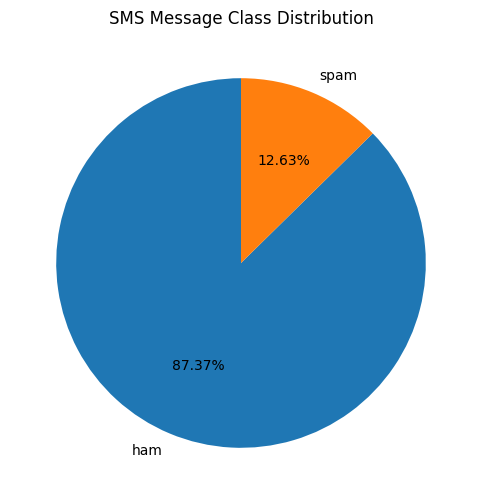

In [27]:
data['Target'].value_counts().plot(
    kind='pie',
    autopct='%1.2f%%',
    figsize=(6, 6),
    startangle=90
)

plt.ylabel('')
plt.title('SMS Message Class Distribution')
plt.show()

In [18]:
data['Target'].value_counts()

Target
ham     4516
spam     653
Name: count, dtype: int64

In [20]:
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to C:\Users\VIP
[nltk_data]     Company\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\VIP
[nltk_data]     Company\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [21]:
data['num_words']=data['Text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [22]:
data.head()

,Target,Text,num_words
0,ham,"Go until jurong point, crazy.. Available only ...",24
1,ham,Ok lar... Joking wif u oni...,8
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,37
3,ham,U dun say so early hor... U c already then say...,13
4,ham,"Nah I don't think he goes to usf, he lives aro...",15


In [23]:
data.groupby('Target')['num_words'].describe()

,count,mean,std,min,25%,50%,75%,max
Target,,,,,,,,
ham,4516.0,17.275465,13.586125,1.0,8.0,13.0,22.0,220.0
spam,653.0,27.754977,6.980780,2.0,25.0,29.0,32.0,46.0


In [25]:
import seaborn as sns

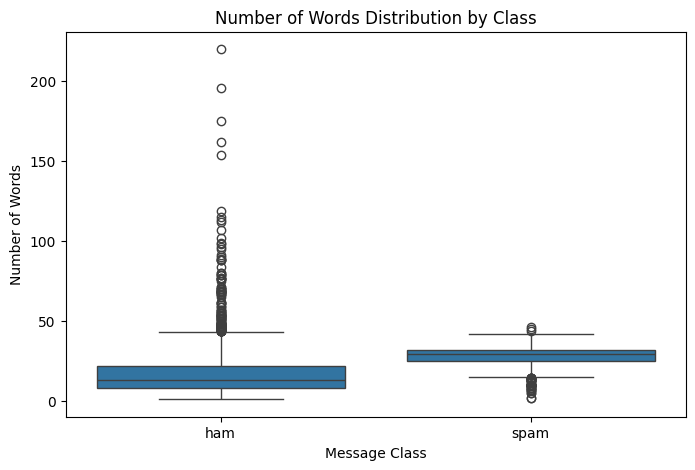

In [26]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=data, x='Target', y='num_words')

plt.title('Number of Words Distribution by Class')
plt.xlabel('Message Class')
plt.ylabel('Number of Words')

plt.show()


In [28]:
#data preprosissing
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to C:\Users\VIP
[nltk_data]     Company\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [29]:

from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
import nltk
import re
import string

ps = PorterStemmer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', '', text)
    tokens = nltk.word_tokenize(text)

    cleaned_text = []
    for word in tokens:
        if word.isalpha():
            if word not in stop_words:
                cleaned_text.append(ps.stem(word))

    return " ".join(cleaned_text)


In [31]:
clean_text('FREE RINGTONE text?  FIRST to 87131 for  the a <fttyty?> poly or text GET&gf764744 to 87131 for a true tone! Help? 0845 2814032 16 after 1st free, tones are 3xå£150pw to eå£nd txt stop')

'free rington text first poli text get true tone help free tone txt stop'

In [32]:
data['Cleaned_Text'] = data['Text'].apply(clean_text)

In [34]:
data.head()

,Target,Text,num_words,Cleaned_Text
0,ham,"Go until jurong point, crazy.. Available only ...",24,go jurong point crazi avail bugi n great world...
1,ham,Ok lar... Joking wif u oni...,8,ok lar joke wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,37,free entri wkli comp win fa cup final tkt may ...
3,ham,U dun say so early hor... U c already then say...,13,u dun say earli hor u c alreadi say
4,ham,"Nah I don't think he goes to usf, he lives aro...",15,nah think goe usf live around though


In [35]:
(data['Cleaned_Text'].str.strip() == '').sum()

np.int64(11)

In [36]:
empty_messages = data[data['Cleaned_Text'].str.strip() == '']

empty_messages[['Text', 'Cleaned_Text', 'Target']]

,Text,Cleaned_Text,Target
252,What you doing?how are you?,,ham
959,Where @,,ham
1611,645,,ham
2805,Can a not?,,ham
3092,staff.science.nus.edu.sg/~phyhcmk/teaching/pc1323,,ham
3374,:),,ham
3740,2/2 146tf150p,,spam
4291,G.W.R,,ham
4573,:( but your not here....,,ham
4822,:-) :-),,ham


In [37]:
empty_messages['Target'].value_counts()

Target
ham     10
spam     1
Name: count, dtype: int64

In [38]:
data = data[data['Cleaned_Text'].str.strip() != '']

data.shape

(5158, 4)

In [39]:
from sklearn.preprocessing import LabelEncoder
encoder =LabelEncoder()
data['Target']=encoder.fit_transform(data['Target'])

In [40]:
data.sample(10)



,Target,Text,num_words,Cleaned_Text
2432,0,Really dun bluff me leh... U sleep early too. ...,13,realli dun bluff leh u sleep earli nite
838,1,We tried to contact you re our offer of New Vi...,28,tri contact offer new video phone anytim netwo...
4687,0,Hmmm.but you should give it on one day..,9,give one day
4834,0,"OH RITE. WELL IM WITH MY BEST MATE PETE, WHO I...",31,oh rite well im best mate pete went longer week
4788,0,We're on the opposite side from where we dropp...,12,opposit side drop
3119,0,Good evening! this is roger. How are you?,11,good even roger
956,0,"Love isn't a decision, it's a feeling. If we c...",31,love decis feel could decid love life would mu...
915,0,I could ask carlos if we could get more if any...,15,could ask carlo could get anybodi els chip
5160,0,Ok... Then r we meeting later?,8,ok r meet later
5312,0,Here got ur favorite oyster... N got my favori...,25,got ur favorit oyster n got favorit sashimi ok...


In [42]:
from sklearn.model_selection import train_test_split
X = data['Cleaned_Text']
y = data['Target']
x_train, x_test, y_train, y_test = train_test_split(data['Cleaned_Text'],data['Target'],test_size=0.15,random_state=42,stratify=data['Target'])

In [45]:
print(x_train.shape)
print(x_test.shape)

print(y_train.shape)
print(y_test.shape)

(4384,)
(774,)
(4384,)
(774,)
